# Mini2P dynamic stripe removal

This notebook is for stripe artifacts that change/pulsate over time, so a fixed stripe template is not enough.

It estimates a stripe profile separately for each frame, while trying not to remove biological signal by:

1. using dim/background pixels,
2. collapsing each frame into a 1D row/column profile,
3. subtracting a broad spatial trend,
4. keeping only the stripe-scale component,
5. subtracting that component from the frame.

It reads the TIFF page-by-page in chunks, so it should not load the whole stack into RAM.

Assumed raw TIFF shape: `frames x height x width`.

For your file this looked like `(21820, 512, 512)`.

In [1]:
import os
import gc
import numpy as np
import tifffile
import matplotlib.pyplot as plt

try:
    from scipy.ndimage import gaussian_filter1d
except ImportError:
    raise ImportError("Install scipy first: pip install scipy  or  conda install scipy")

# ----------------------------
# User settings
# ----------------------------
path = "/Users/megyoung/Desktop/mini2p Images/72Lgoodtask"  # CHANGE THIS
selected_tiff = "72ltask_00001.tif"  # CHANGE THIS if needed

tiff_path = os.path.join(path, selected_tiff)

# Which interleaved channel is GCaMP / functional?
# 0 means raw frames 0, 2, 4, ...
# 1 means raw frames 1, 3, 5, ...
signal_channel = 1

# "column" = vertical stripes, one correction value per x-column
# "row"    = horizontal stripes, one correction value per y-row
stripe_axis = "column"

# Lower if kernel crashes
chunk_size = 25

base = os.path.splitext(selected_tiff)[0]

In [2]:
# ----------------------------
# Inspect TIFF without loading whole thing
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Raw frames:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

signal_frames = np.arange(signal_channel, n_pages, 2)
print("Signal frames:", len(signal_frames))

Raw frames: 21820
Height: 512
Width: 512
dtype: int16
Signal frames: 10910


In [3]:
def read_pages_from_open_tif(tif, frame_indices):
    return np.stack([tif.pages[int(i)].asarray() for i in frame_indices], axis=0)


def robust_rescale_for_display(img, low=1, high=99):
    img = img.astype(np.float32)
    vmin, vmax = np.nanpercentile(img, [low, high])
    return np.clip((img - vmin) / (vmax - vmin + 1e-8), 0, 1)


def fill_nan_profile(profile):
    x = np.arange(profile.size)
    good = np.isfinite(profile)

    if np.sum(good) == 0:
        return np.zeros_like(profile, dtype=np.float32)

    if np.sum(good) == 1:
        return np.full_like(profile, profile[good][0], dtype=np.float32)

    return np.interp(x, x[good], profile[good]).astype(np.float32)


def preview_interleaved_channel(tiff_path, channel, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(channel, min(n_pages, channel + 2 * n_frames), 2)
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img

In [4]:
def estimate_dynamic_stripe_profile(
    frame,
    axis="column",
    background_percentile=30,
    broad_sigma=15,
    stripe_smooth_sigma=1
):
    frame = frame.astype(np.float32)

    thresh = np.nanpercentile(frame, background_percentile)
    mask = frame <= thresh

    if axis == "column":
        n = frame.shape[1]
        profile = np.full(n, np.nan, dtype=np.float32)

        for x in range(n):
            vals = frame[:, x][mask[:, x]]
            if vals.size > 0:
                profile[x] = np.nanmedian(vals)

    elif axis == "row":
        n = frame.shape[0]
        profile = np.full(n, np.nan, dtype=np.float32)

        for y in range(n):
            vals = frame[y, :][mask[y, :]]
            if vals.size > 0:
                profile[y] = np.nanmedian(vals)

    else:
        raise ValueError("axis must be 'column' or 'row'")

    profile = fill_nan_profile(profile)

    # Remove broad spatial structure, leaving stripe-scale variation
    broad = gaussian_filter1d(profile, sigma=broad_sigma, mode="nearest")
    stripe = profile - broad

    # Tiny smoothing to avoid creating pixel-noise
    if stripe_smooth_sigma is not None and stripe_smooth_sigma > 0:
        stripe = gaussian_filter1d(stripe, sigma=stripe_smooth_sigma, mode="nearest")

    stripe = stripe - np.nanmedian(stripe)

    return stripe.astype(np.float32)


def correct_frame_dynamic_stripe(
    frame,
    axis="column",
    background_percentile=30,
    broad_sigma=15,
    stripe_smooth_sigma=1,
    correction_strength=0.75,
    preserve_baseline=True,
):
    frame = frame.astype(np.float32)

    stripe = estimate_dynamic_stripe_profile(
        frame,
        axis=axis,
        background_percentile=background_percentile,
        broad_sigma=broad_sigma,
        stripe_smooth_sigma=stripe_smooth_sigma,
    )

    if axis == "column":
        corrected = frame - correction_strength * stripe[None, :]
    else:
        corrected = frame - correction_strength * stripe[:, None]

    if preserve_baseline:
        corrected = corrected - np.nanmedian(corrected) + np.nanmedian(frame)

    return corrected, stripe


def correct_chunk_dynamic_stripe(
    chunk,
    axis="column",
    background_percentile=30,
    broad_sigma=15,
    stripe_smooth_sigma=1,
    correction_strength=0.75,
    preserve_baseline=True,
):
    chunk = chunk.astype(np.float32)
    corrected = np.empty_like(chunk, dtype=np.float32)
    stripe_profiles = []

    for i in range(chunk.shape[0]):
        corrected[i], stripe = correct_frame_dynamic_stripe(
            chunk[i],
            axis=axis,
            background_percentile=background_percentile,
            broad_sigma=broad_sigma,
            stripe_smooth_sigma=stripe_smooth_sigma,
            correction_strength=correction_strength,
            preserve_baseline=preserve_baseline,
        )
        stripe_profiles.append(stripe)

    return corrected, np.stack(stripe_profiles, axis=0)

## Test parameters on a small preview before running the full stack

Good first tests:

```python
background_percentile = 30
broad_sigma = 8
correction_strength = 0.75
```

```python
background_percentile = 30
broad_sigma = 15
correction_strength = 0.75
```

```python
background_percentile = 20
broad_sigma = 15
correction_strength = 0.5
```

For Suite2p, this notebook saves as `uint16` by default because Suite2p usually behaves better with non-zero-centered integer TIFFs than with float, mean-subtracted TIFFs.

In [19]:
# ----------------------------
# Preview parameters
# ----------------------------
background_percentile = 70
broad_sigma = 5
stripe_smooth_sigma = 1
correction_strength = 2
preseve_baseline = True

preview_start = 0
preview_n_frames = 200

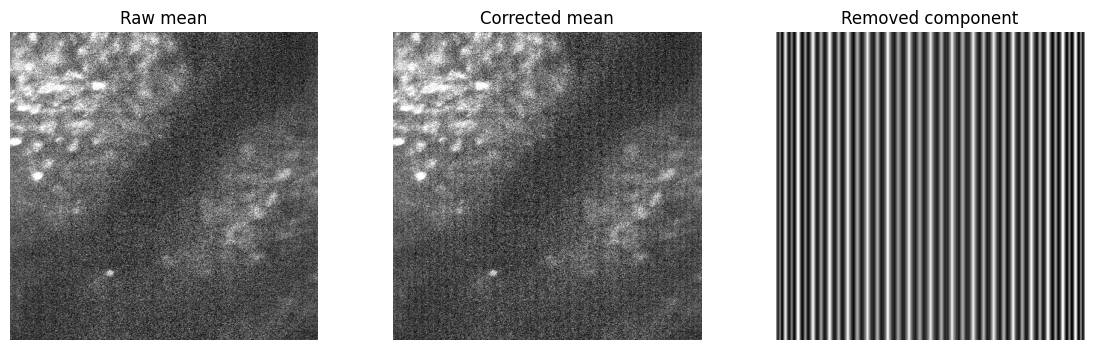

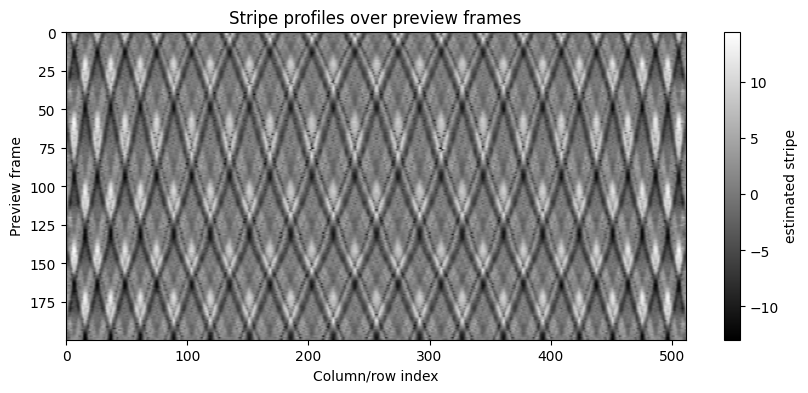

15428

In [20]:
# ----------------------------
# Preview correction on a small number of frames
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    signal_frames = np.arange(signal_channel, n_pages, 2)

    preview_inds = signal_frames[preview_start:preview_start + preview_n_frames]
    preview_chunk = read_pages_from_open_tif(tif, preview_inds).astype(np.float32)

corrected_preview_chunk, stripe_profiles = correct_chunk_dynamic_stripe(
    preview_chunk,
    axis=stripe_axis,
    background_percentile=background_percentile,
    broad_sigma=broad_sigma,
    stripe_smooth_sigma=stripe_smooth_sigma,
    correction_strength=correction_strength,
    preserve_baseline=preserve_baseline,
)

raw_mean = np.mean(preview_chunk, axis=0)
corrected_mean = np.mean(corrected_preview_chunk, axis=0)
removed_mean = raw_mean - corrected_mean

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(raw_mean), cmap="gray")
plt.title("Raw mean")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(corrected_mean), cmap="gray")
plt.title("Corrected mean")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(removed_mean), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

plt.figure(figsize=(10, 4))
plt.imshow(stripe_profiles, aspect="auto", cmap="gray")
plt.title("Stripe profiles over preview frames")
plt.xlabel("Column/row index")
plt.ylabel("Preview frame")
plt.colorbar(label="estimated stripe")
plt.show()

del preview_chunk, corrected_preview_chunk
gc.collect()

Raw mean range: [ 66.94999695  92.25499725 141.42784714]
Corrected mean range: [ 67.2902887   92.64942169 141.74950027]
Removed range: [-1.17923737 -0.47868729  0.76902771]


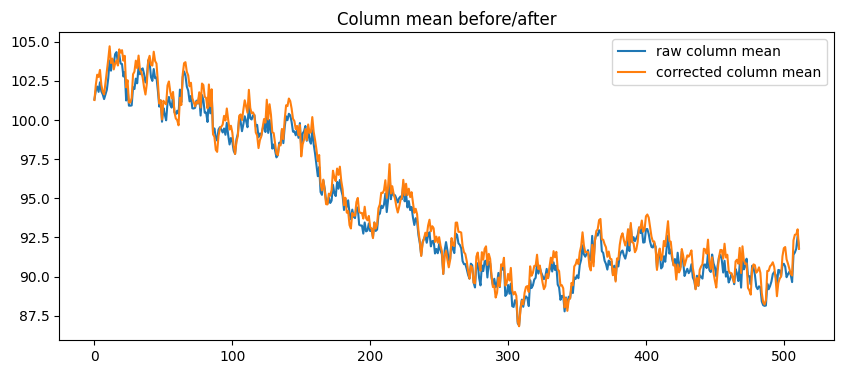

In [18]:
print("Raw mean range:", np.percentile(raw_mean, [1, 50, 99]))
print("Corrected mean range:", np.percentile(corrected_mean, [1, 50, 99]))
print("Removed range:", np.percentile(removed_mean, [1, 50, 99]))

plt.figure(figsize=(10,4))
plt.plot(np.mean(raw_mean, axis=0), label="raw column mean")
plt.plot(np.mean(corrected_mean, axis=0), label="corrected column mean")
plt.legend()
plt.title("Column mean before/after")
plt.show()

In [ ]:
def convert_for_suite2p(chunk, output_dtype=np.uint16):
    if output_dtype == np.uint16:
        return np.clip(chunk, 0, 65535).astype(np.uint16)

    if output_dtype == np.int16:
        info = np.iinfo(np.int16)
        return np.clip(chunk, info.min, info.max).astype(np.int16)

    return chunk.astype(output_dtype)


def run_dynamic_stripe_correction(
    tiff_path,
    signal_channel,
    output_file,
    chunk_size=25,
    axis="column",
    background_percentile=30,
    broad_sigma=15,
    stripe_smooth_sigma=1,
    correction_strength=0.75,
    preserve_baseline=True,
    output_dtype=np.uint16,
):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        signal_frames = np.arange(signal_channel, n_pages, 2)
        n = len(signal_frames)

        print("Saving to:", output_file)
        print("Frames to save:", n)

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, n, chunk_size):
                end = min(start + chunk_size, n)
                inds = signal_frames[start:end]

                chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

                corrected, stripe_profiles = correct_chunk_dynamic_stripe(
                    chunk,
                    axis=axis,
                    background_percentile=background_percentile,
                    broad_sigma=broad_sigma,
                    stripe_smooth_sigma=stripe_smooth_sigma,
                    correction_strength=correction_strength,
                    preserve_baseline=preserve_baseline,
                )

                corrected_to_save = convert_for_suite2p(corrected, output_dtype=output_dtype)
                writer.write(corrected_to_save, photometric="minisblack")

                print(f"Saved frames {start} to {end} / {n}")

                del chunk, corrected, corrected_to_save, stripe_profiles
                gc.collect()

    print("Done:", output_file)

In [ ]:
# ----------------------------
# Run full correction and save new TIFF
# ----------------------------
output_file = os.path.join(
    path,
    f"{base}_unstriped_dynamic_ch{signal_channel}_bg{background_percentile}_sigma{broad_sigma}_strength{correction_strength}.tiff"
)

run_dynamic_stripe_correction(
    tiff_path=tiff_path,
    signal_channel=signal_channel,
    output_file=output_file,
    chunk_size=chunk_size,
    axis=stripe_axis,
    background_percentile=background_percentile,
    broad_sigma=broad_sigma,
    stripe_smooth_sigma=stripe_smooth_sigma,
    correction_strength=correction_strength,
    preserve_baseline=preserve_baseline,
    output_dtype=np.uint16,
)

In [ ]:
# ----------------------------
# Preview saved output
# ----------------------------
def preview_saved_tiff(tiff_path, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(0, min(n_pages, n_frames))
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img


saved_preview = preview_saved_tiff(output_file, n_frames=200)
raw_preview = preview_interleaved_channel(tiff_path, signal_channel, n_frames=200)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(raw_preview), cmap="gray")
plt.title("Raw signal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(saved_preview), cmap="gray")
plt.title("Saved dynamic corrected")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(raw_preview - saved_preview), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

print("Saved corrected TIFF:")
print(output_file)